# Historical Alpha Discovery v1 — 실제 KR 데이터 탐색

**결론:** 장중 상승 경로의 추가 예측력은 일관되지 않았다. 6개월 주 전략은 보유 중 정지·가격 기준 미해결 때문에 전체 기간 NAV를 계산하지 않았다. 계산 가능한 12개월 야간 수익 대조 전략은 ETF보다 낮은 수익률과 Sharpe, 더 큰 낙폭을 보였다.

`EXPLORATORY_ON_PREVIOUSLY_EXPOSED_HISTORY`. 기존 연구의 독립 OOS나 검증된 추천이 아니다. 아래 그래프는 **주 전략이 아니라 사전에 정한 대조군**이다. 종목 수익은 불완전 배당 누적 지수이고 ETF는 총배당 기준이므로 완전한 총수익 대등 비교가 아니다.

## 방법과 원천

- main `591f182955ab85bc527ddedc41c2d77d1fd24eaa`, signal-history `a0a31895699aacaf3f8f30401b348703e39088b7`.
- 명세·코드 첫 고정 `dc73bae`: 실제 신규 수익 계산 전에 저장. 기존 봉인 실행기를 호출하지 않았다.
- 전일 확정 신호 → 다음 KRX 세션 종가 체결, 126/252 세션 비중첩 보유. 고정 규칙으로 학습·튜닝 없음.
- 과거 날짜의 Top120, 선호주 이름 제외, 253개 연속 관측, 유동성 proxy, 업종당 최대 2개·총 5개, 부족 슬롯 ETF. 2019 이전과 21세션 이상 엠바고 뒤 2020년 이후를 별도 계산.
- 수수료+반스프레드 편도 11.5bp, 매도 연도별 세금; 2배 비용도 전부 계산. ETF 대조군은 분석 기간 시작·끝에만 거래.
- 보유 중 정지·누락·종결 대가 미해결은 전체 책 차단. 결과를 알고 종목을 교체하거나 유효 블록을 연결하지 않음.
- 별도 `EX_POST_CONTINUING_NAME_CONDITIONAL` 표본은 알려진 종료 22종목+006800을 미래 신원으로 제외한 **생존자 조건부 민감도**이며 당시 실행 가능한 표본이 아님.
- Sharpe의 현금 수익률=0; 소수 주식 단위·세전 배당 누적·종가 체결 가정으로 실제 계좌 수익이 아님.

이 노트북은 저장된 새 연구 결과를 읽고 독립 산술 검증한다. 실험 재실행 명령은 README에 있다. 모든 원천 파일 해시는 summary.json에 기록했다.

In [1]:
from pathlib import Path
import json, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
root = Path.cwd()/"research/historical_alpha_discovery_v1"
if not root.exists(): root=Path.cwd()
results=root/"results"
summary=json.loads((results/"summary.json").read_text())
blocks=pd.read_json(results/"blocks.json")
diag=json.loads((results/"diagnostics/diagnostics.json").read_text())
plt.rcParams.update({"figure.figsize":(11,7),"font.size":11,"axes.spines.top":False,"axes.spines.right":False,"axes.grid":True,"grid.alpha":.18})
comparison=[]
for row in summary["portfolios"]:
    if row["analysisWindow"]=="EVALUATION_2020_AFTER_EMBARGO" and row["sample"].startswith("PIT") and row["horizon"]==252 and row["costMultiplier"]==1:
        metrics=row["metrics"]
        comparison.append({"book":row["book"],"status":"COMPLETE_PROXY_PATH" if row["complete"] else "BLOCKED","CAGR %":None if metrics is None else metrics["cagr"]*100,"Sharpe rf=0":None if metrics is None else metrics["sharpeZeroRf"],"MDD %":None if metrics is None else metrics["mdd"]*100,"daily CVaR95 %":None if metrics is None else metrics["dailyCvar95"]*100})
display(pd.DataFrame(comparison).round(3))

,book,status,CAGR %,Sharpe rf=0,MDD %,daily CVaR95 %
0,ETF,COMPLETE_PROXY_PATH,36.454,1.449,-34.328,-3.286
1,MOMENTUM,BLOCKED,NaN,NaN,NaN,NaN
2,INTRADAY,BLOCKED,NaN,NaN,NaN,NaN
3,OVERNIGHT,COMPLETE_PROXY_PATH,28.281,0.870,-43.034,-4.881
4,HALF_INTRADAY_HALF_ETF,BLOCKED,NaN,NaN,NaN,NaN


## 완료된 비교

같은 2020-03-30~2026-06-01, 1,512 일간 관측과 6개 연간 보유 블록. 다른 차단 전략에 이 결과를 대입하지 않는다. 이 시작일은 2014년 고정 원점의 달력 간격으로 정해졌으며 일반적인 2020년 연초 성과가 아니다.

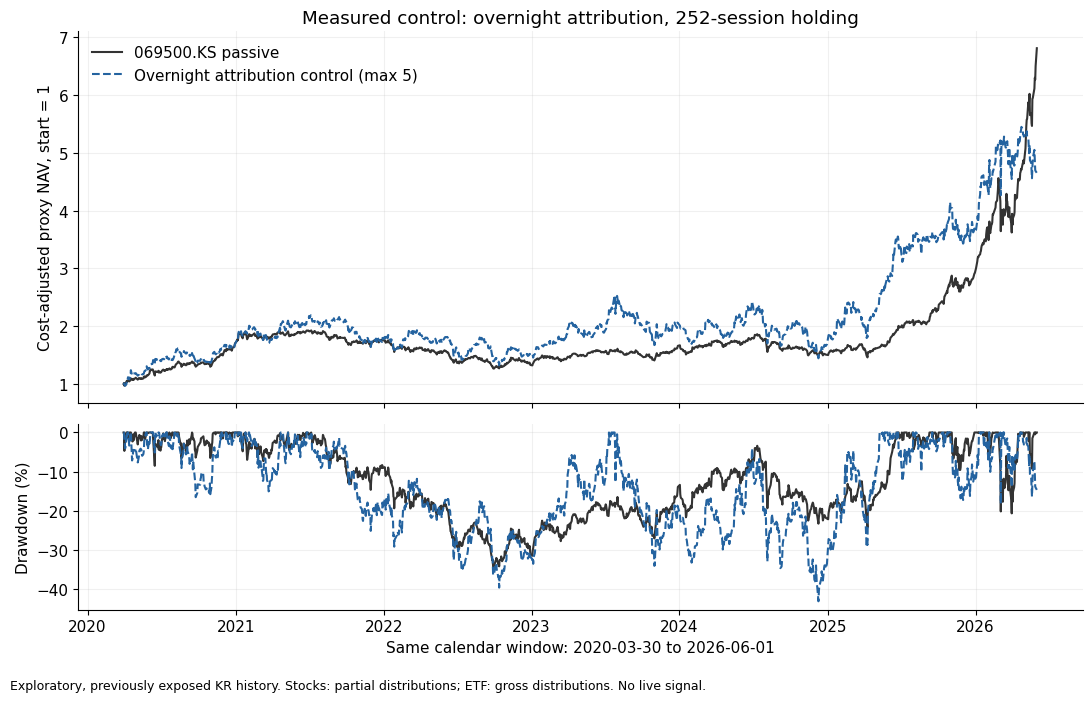

In [2]:
fig,axes=plt.subplots(2,1,sharex=True,figsize=(11,7),gridspec_kw={"height_ratios":[2,1]})
for book,color,style,label in [("ETF","#333333","-","069500.KS passive"),("OVERNIGHT","#2463a0","--","Overnight attribution control (max 5)")]:
    name=f"nav-EVALUATION_2020_AFTER_EMBARGO-PIT_WITH_UNRESOLVED_PATHS_BLOCKED-252-1-{book}.csv"
    frame=pd.read_csv(results/name,parse_dates=["date"])
    axes[0].plot(frame.date,frame.nav,color=color,ls=style,label=label)
    axes[1].plot(frame.date,100*(frame.nav/frame.nav.cummax()-1),color=color,ls=style)
axes[0].set_ylabel("Cost-adjusted proxy NAV, start = 1")
axes[0].set_title("Measured control: overnight attribution, 252-session holding")
axes[0].legend(frameon=False,loc="upper left")
axes[1].set_ylabel("Drawdown (%)")
axes[1].set_xlabel("Same calendar window: 2020-03-30 to 2026-06-01")
fig.text(.01,.005,"Exploratory, previously exposed KR history. Stocks: partial distributions; ETF: gross distributions. No live signal.",fontsize=9)
fig.tight_layout(rect=[0,.03,1,1])
fig.savefig(results/"measured-control.png",dpi=150)
plt.show()

## 주 가설과 관측 가능성

다음 표의 비교는 **유효한 쌍만의 기술통계**다. 전체 투자 경로 수익률이 아니며, 누락된 블록·종목 위험을 일반화할 수 없다. H252는 유효 쌍이 적어 구간을 계산하지 않았다. H126 구간도 독립 확증이 아닌 연도 군집 부트스트랩 기술 구간이다.

In [3]:
paired=[]
for row in summary["intradayVsMomentum"]:
    if row["analysisWindow"]=="FULL" and row["sample"].startswith("PIT") and row["book"]=="INTRADAY" and row["costMultiplier"]==1:
        interval=row["descriptiveYearBootstrap95"]
        paired.append({"H":row["horizon"],"valid pairs":row["validPairs"],"scheduled blocks":row["scheduledBlocks"],"mean block difference (pp)":100*row["meanBlockExcess"],"descriptive 95% (pp)":None if interval is None else [round(100*x,2) for x in interval]})
display(pd.DataFrame(paired))
display(pd.DataFrame(diag["featureIC"]))
coverage=pd.read_json(results/"coverage.json")
coverage=coverage[(coverage.analysisWindow=="FULL") & (coverage.horizon==126) & coverage["sample"].str.startswith("PIT")]
print("H126 scheduled name-dates:",int(coverage.members.sum()),"measurable:",int(coverage.measurable.sum()))
display(pd.DataFrame(diag["blockedPrimaryH126"])[["entry","ticker","reason","zeroVolumeSessions","firstZeroVolume","lastZeroVolume"]])

,H,valid pairs,scheduled blocks,mean block difference (pp),descriptive 95% (pp)
0,126,19,24,1.985498,"[-8.41, 16.69]"
1,252,7,12,0.439515,None


,horizon,feature,scheduledDates,validDates,validNameDateCount,meanDateIC,inference
0,126,intraday,24,24,2371,0.010295,NONE_EXPOSED_HISTORY_AND_FEW_NONOVERLAPPING_DATES
1,126,momentum,24,24,2371,0.006749,NONE_EXPOSED_HISTORY_AND_FEW_NONOVERLAPPING_DATES
2,126,overnight,24,24,2371,-0.017558,NONE_EXPOSED_HISTORY_AND_FEW_NONOVERLAPPING_DATES
3,252,intraday,12,12,1167,0.024325,NONE_EXPOSED_HISTORY_AND_FEW_NONOVERLAPPING_DATES
4,252,momentum,12,12,1167,-0.057242,NONE_EXPOSED_HISTORY_AND_FEW_NONOVERLAPPING_DATES
5,252,overnight,12,12,1167,-0.039726,NONE_EXPOSED_HISTORY_AND_FEW_NONOVERLAPPING_DATES


H126 scheduled name-dates: 2880 measurable: 2419


,entry,ticker,reason,zeroVolumeSessions,firstZeroVolume,lastZeroVolume
0,2015-02-10,002790.KS,SUSPENDED_OR_UNTRADED_VALUATION_SESSION,10,2015-04-22,2015-05-07
1,2015-02-10,090430.KS,SUSPENDED_OR_UNTRADED_VALUATION_SESSION,10,2015-04-22,2015-05-07
2,2022-10-19,009830.KS,SUSPENDED_OR_UNTRADED_VALUATION_SESSION,23,2023-02-27,2023-03-30
3,2024-04-30,012450.KS,SUSPENDED_OR_UNTRADED_VALUATION_SESSION,18,2024-08-29,2024-09-26
4,2025-05-19,006800.KS,KNOWN_UNRESOLVED_PRICE_BASIS,0,None,None


## 재현·독립 산술 검증

완료된 모든 NAV에 대해 블록 수익률의 곱을 별도로 계산해 총수익과 대조한다. 결과를 정당화하기 위해 기존 Phase C/C1 실행기를 호출하지 않는다.

In [4]:
checked=0
for row in summary["portfolios"]:
    if not row["complete"]:
        assert row["metrics"] is None
        continue
    mask=np.ones(len(blocks),dtype=bool)
    for key in ["analysisWindow","sample","horizon","costMultiplier","book"]:
        mask &= blocks[key].eq(row[key]).to_numpy()
    subset=blocks.loc[mask]
    assert subset.netReturn.notna().all()
    compound=math.prod(1+x for x in subset.netReturn)-1
    assert abs(compound-row["metrics"]["totalReturn"])<1e-8
    checked+=1
print("Independent compound reconciliations:",checked)
print(json.dumps(json.loads((results/"execution-log.json").read_text())["reproduction"],indent=2))

Independent compound reconciliations: 30
{
  "runtime": {
    "python": "3.12.14",
    "numpy": "2.3.1",
    "pandas": "2.3.0",
    "exchangeCalendars": "4.11.1"
  },
  "codeSha256": "ea4209a1890114e7b7cd3b30fa49ecede5d863dada20b1eb3267ae246d0ef7b9",
  "maximumFinancialDifference": 0,
  "sameSpec": true,
  "sameSourceBytes": true,
  "completePathsChecked": 30,
  "maximumIndependentCompoundReconciliationGap": 8.02439892311213e-10
}


## 투자 연구에서 새로 배운 것

1. 단순 종가 모멘텀과 장중·야간 귀속은 동일하지 않지만, 이 표본에서 안정적인 추가 알파를 입증하지 못했다. H126 장중 우위의 기술 구간은 0을 포함하고 H252에서는 표본과 방향 안정성이 부족하다.
2. 계산 가능한 연간 야간 대조군은 ETF에 CAGR 약 8.17%p/년 뒤지고 위험도 높았다. 그 전략을 채택할 근거가 없다.
3. 전체 데이터를 모두 복구하지 않고도 실제 비교는 가능했다. 반면 주 전략의 경제성은 몇 개 선택 종목의 정지·권리/가격 기준 때문에 아직 확정할 수 없다. 임의 보간으로 이를 통과시키지 않았다.
4. 다음 한 작업은 새 특징·모델 확대보다, 이 실험이 실제 보유한 정지 종목의 분할·배포 권리와 재개 가격 기준을 기존 보존 문서로 연결하는 것이다. 이후 동일 고정 책을 별도 버전에서 검증해야 한다. 기존 봉인 결과는 그대로 둔다.

현재 종목 추천이나 생산 주문 신호는 생성하지 않았다.